# Matrizes Aleatórias

* PET - Física
* Petiano: Wallysson Pereira da Silva
* Data: 03/02/2025

$\quad$ Resumminho papapa

## Importando bibliotecas

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Informações sobre as bibliotecas

In [ ]:
%load_ext version_information
%version_information Matplotlib, Numpy

Software versions
Python 3.12.7 64bit [MSC v.1929 64 bit (AMD64)]
IPython 8.29.0
OS Windows 11 10.0.26200 SP0
Matplotlib 3.9.2
Numpy 2.1.3
Wed Aug 12 09:50:50 2026 Hora oficial do Brasil

## 1. O que é uma Matrix Aleatória?

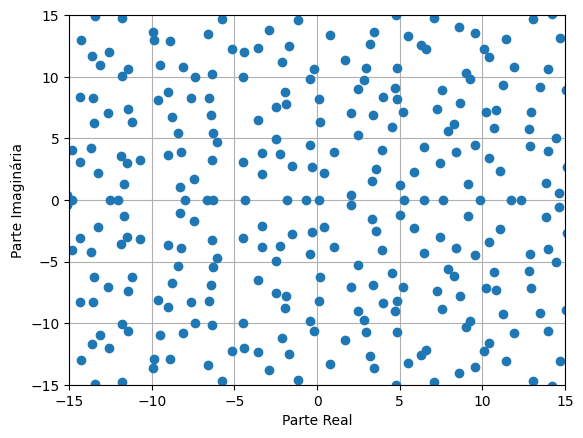

In [ ]:
N = 1000
matrix = np.zeros([N,N])

for i in range(0, N):
    for j in range(0,N):
        A_ij = np.random.normal(loc = 0, scale = 1)
        matrix[i][j] = A_ij

autovalores, autovetores = np.linalg.eig(matrix)
parte_real = autovalores.real
parte_imag = autovalores.imag


plt.plot(parte_real, parte_imag, "o")
d = 100
plt.xlim(-d, d)
plt.ylim(-d, d)
plt.xlabel("Parte Real")
plt.ylabel("Parte Imaginária")
plt.grid()
plt.show()

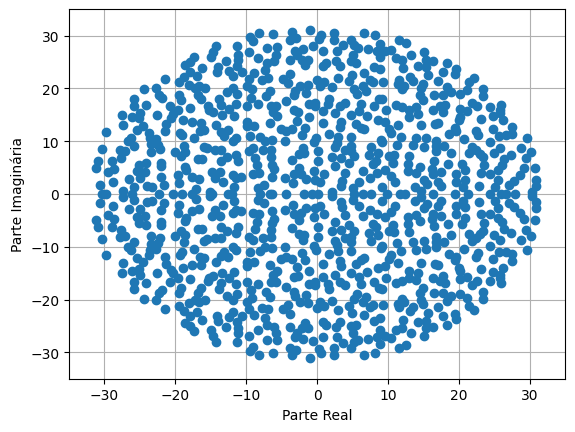

In [49]:

plt.plot(parte_real, parte_imag, "o")
d = 35
plt.xlim(-d, d)
plt.ylim(-d, d)
plt.xlabel("Parte Real")
plt.ylabel("Parte Imaginária")
plt.grid()
plt.show()

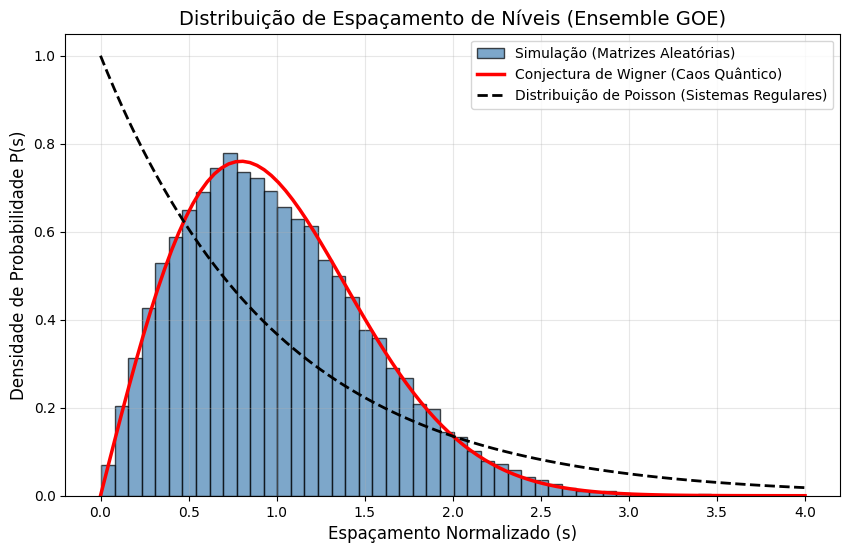

In [54]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parâmetros da Simulação
N = 100       # Tamanho da matriz (N x N)
M = 500       # Número de matrizes geradas no ensemble para termos boa estatística

spacings = []

for _ in range(M):
    # Gerar uma matriz aleatória com distribuição Gaussiana
    A = np.random.randn(N, N)
    
    # Tornar a matriz simétrica (Hamiltoniano Hermitiano Real -> GOE)
    H = (A + A.T) / 2.0
    
    # Calcular os autovalores (níveis de energia)
    eigenvalues = np.linalg.eigvalsh(H)
    
    # Isolar os autovalores centrais (bulk) para evitar distorções das bordas do espectro
    bulk_eigenvalues = eigenvalues[int(N*0.25):int(N*0.75)]
    
    # Calcular o espaçamento entre níveis de energia adjacentes
    diffs = np.diff(bulk_eigenvalues)
    spacings.extend(diffs)

# 2. Normalizar os espaçamentos (fazer a média = 1)
spacings = np.array(spacings)
s = spacings / np.mean(spacings)

# 3. Preparar a visualização
plt.figure(figsize=(10, 6))

# Plotar o histograma dos dados gerados
plt.hist(s, bins=50, density=True, alpha=0.7, color='steelblue', 
         edgecolor='black', label='Simulação (Matrizes Aleatórias)')

# 4. Adicionar a Curva Teórica: Conjectura de Wigner (Wigner Surmise)
s_line = np.linspace(0, 4, 100)
p_wigner = (np.pi / 2) * s_line * np.exp(- (np.pi / 4) * s_line**2)
plt.plot(s_line, p_wigner, 'r-', lw=2.5, label='Conjectura de Wigner (Caos Quântico)')

# Adicionar a Curva de Poisson (Sistemas Integráveis/Não-caóticos)
p_poisson = np.exp(-s_line)
plt.plot(s_line, p_poisson, 'k--', lw=2, 
         label='Distribuição de Poisson (Sistemas Regulares)')

# Formatações do gráfico
plt.title('Distribuição de Espaçamento de Níveis (Ensemble GOE)', fontsize=14)
plt.xlabel('Espaçamento Normalizado (s)', fontsize=12)
plt.ylabel('Densidade de Probabilidade P(s)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.show()

## 3. Aplicação

# Referências 

**[]** ....